# GPU Inference Execution Path & System-Level Bottleneck Identification
**Runtime:** Google Colab → *Runtime ▸ Change runtime type ▸ T4 GPU*

## The execution path we are measuring
```
 raw data ─► [1] CPU preprocess ─► [2] H2D copy (PCIe) ─► [3] GPU compute (kernel launches + execution)
                                                              │
 final answer ◄─ [5] CPU postprocess ◄─ [4] D2H copy (PCIe) ◄─┘
```
Memory trick for revision: think of a **restaurant**. CPU = the waiter prepping the order, PCIe = the corridor to the kitchen, GPU = the kitchen. A fast kitchen is useless if the waiter is slow or the corridor is narrow. Bottleneck hunting = finding which of the five stages the customer actually waits on.

**Notebook plan:** (1) environment → (2) stage-by-stage timing → (3) batch-size sweep → (4) fix-and-compare experiments → (5) launch overhead / GPU idle → (6) kernel-level profiler → (7) roofline-style utilisation → (8) automatic bottleneck verdict.

In [1]:
import torch, time, copy, math, subprocess, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torchvision

assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > T4 GPU"
dev = torch.device("cuda")
props = torch.cuda.get_device_properties(0)
print("GPU            :", props.name)
print("SMs            :", props.multi_processor_count)
print("VRAM           : %.1f GB" % (props.total_memory / 1e9))
print("Compute cap.   :", f"{props.major}.{props.minor}")
print("PyTorch / CUDA :", torch.__version__, "/", torch.version.cuda)
print(subprocess.run(["nvidia-smi", "--query-gpu=name,pcie.link.gen.current,pcie.link.width.current,clocks.sm,clocks.mem",
                      "--format=csv"], capture_output=True, text=True).stdout)

GPU            : Tesla T4
SMs            : 40
VRAM           : 15.6 GB
Compute cap.   : 7.5
PyTorch / CUDA : 2.14.1+cu130 / 13.0
name, pcie.link.gen.current, pcie.link.width.current, clocks.current.sm [MHz], clocks.current.memory [MHz]
Tesla T4, 1, 16, 300 MHz, 405 MHz



## 1. Model and helpers
ResNet-50 with random weights is enough: timing depends on architecture and shapes, not on trained values. Swap in your own model (e.g. YOLOv8 from your VisionPort notebook) by editing `make_model()`.

In [2]:
def make_model():
    m = torchvision.models.resnet50(weights=None)
    return m.eval()

base_model = make_model()
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def gpu_peak(name, fp16):
    # approximate vendor peak TFLOPS (fp32 CUDA cores / fp16 tensor cores) and memory GB/s
    table = {"T4": (8.1, 65, 320), "L4": (30.3, 121, 300), "A100": (19.5, 312, 1555),
             "V100": (15.7, 125, 900), "H100": (67, 990, 3350)}
    for k, v in table.items():
        if k in name:
            return (v[1] if fp16 else v[0]), v[2]
    return None, None

## 2. Stage-by-stage timing
CPU stages use `perf_counter`. GPU stages use **CUDA events** (they timestamp on the GPU stream, so they are not fooled by asynchronous launches). We synchronise between stages to *attribute* time cleanly; this serialises the pipeline, so it shows the worst-case, non-overlapped path.

In [3]:
@torch.inference_mode()
def measure(B, pinned=False, fp16=False, channels_last=False, iters=30, warmup=10, model=None):
    model = copy.deepcopy(model or base_model).to(dev)
    dtype = torch.float16 if fp16 else torch.float32
    if fp16: model = model.half()
    if channels_last: model = model.to(memory_format=torch.channels_last)

    raw = torch.randint(0, 255, (B, 3, 224, 224), dtype=torch.uint8)      # "decoded images" in host RAM
    pin_buf = torch.empty((B, 3, 224, 224), dtype=dtype).pin_memory() if pinned else None
    rows = []
    for i in range(warmup + iters):
        # [1] CPU preprocess
        t0 = time.perf_counter()
        x = (raw.float().div_(255) - MEAN) / STD
        x = x.to(dtype)
        if channels_last: x = x.contiguous(memory_format=torch.channels_last)
        t1 = time.perf_counter()

        # [2] H2D
        e = [torch.cuda.Event(enable_timing=True) for _ in range(6)]
        e[0].record()
        if pinned:
            pin_buf.copy_(x)                      # host-side copy into page-locked buffer (CPU cost, counted in H2D wall)
            xg = pin_buf.to(dev, non_blocking=True)
        else:
            xg = x.to(dev)
        e[1].record()

        # [3] GPU compute
        e[2].record()
        y = model(xg)
        e[3].record()

        # [4] D2H
        e[4].record()
        yc = y.float().cpu()
        e[5].record()
        torch.cuda.synchronize()

        # [5] CPU postprocess
        t2 = time.perf_counter()
        probs = torch.softmax(yc, dim=1)
        top5 = probs.topk(5, dim=1)
        t3 = time.perf_counter()

        if i >= warmup:
            rows.append(dict(pre=(t1 - t0) * 1e3, h2d=e[0].elapsed_time(e[1]), gpu=e[2].elapsed_time(e[3]),
                             d2h=e[4].elapsed_time(e[5]), post=(t3 - t2) * 1e3,
                             wall=(t3 - t0) * 1e3))
    df = pd.DataFrame(rows)
    out = df.mean().to_dict()
    out["B"] = B
    out["gpu_busy_%"] = 100 * (out["h2d"] + out["gpu"] + out["d2h"]) / out["wall"]
    out["img_per_s"] = B / out["wall"] * 1e3
    del model, xg, y
    torch.cuda.empty_cache()
    return out

r = measure(B=32)
pd.DataFrame([r]).round(2)

,pre,h2d,gpu,d2h,post,wall,B,gpu_busy_%,img_per_s
0,25.25,4.6,82.44,0.24,0.63,113.38,32,76.98,282.23


## 3. Batch-size sweep: where does the bottleneck move?
Small batches are usually **launch/CPU-bound** (GPU waits to be fed). Large batches become **compute-bound** (GPU is the long pole) or **transfer-bound** if the input is large.

,pre,h2d,gpu,d2h,post,wall,gpu_busy_%,img_per_s
B,,,,,,,,
1,0.36,0.28,7.67,0.08,0.07,8.61,93.28,116.15
2,0.67,0.42,7.25,0.05,0.09,8.60,89.78,232.66
4,1.40,0.69,12.12,0.30,0.13,14.80,88.59,270.25
8,3.05,1.37,24.13,0.17,0.25,29.22,87.85,273.75
16,5.98,2.65,42.73,0.27,0.43,52.35,87.22,305.63
32,11.55,4.64,84.78,0.24,0.63,102.07,87.84,313.51
64,78.04,9.47,173.37,0.31,1.23,262.67,69.73,243.66
128,180.04,20.74,361.39,0.72,2.84,566.07,67.63,226.12


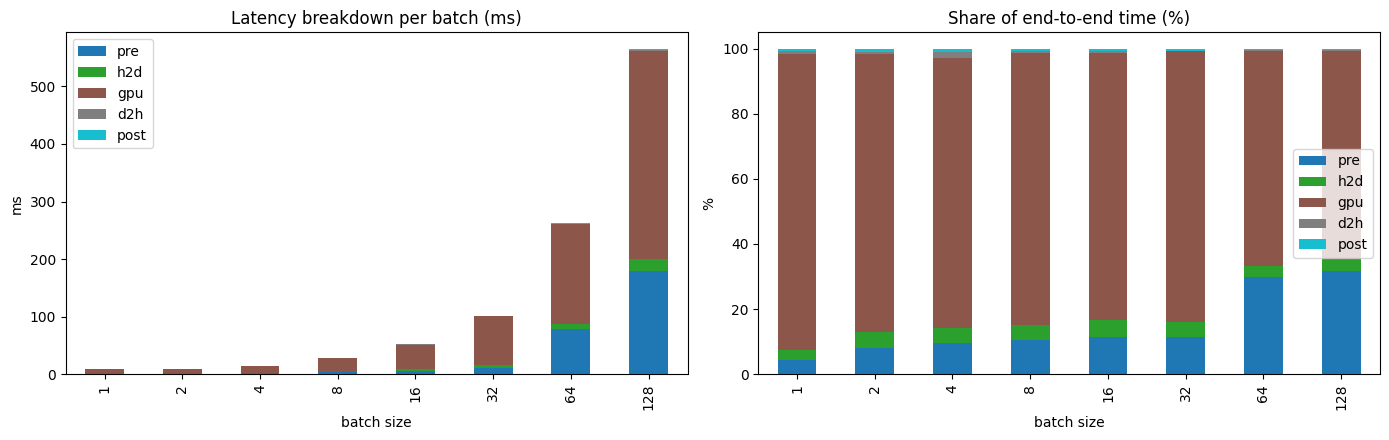

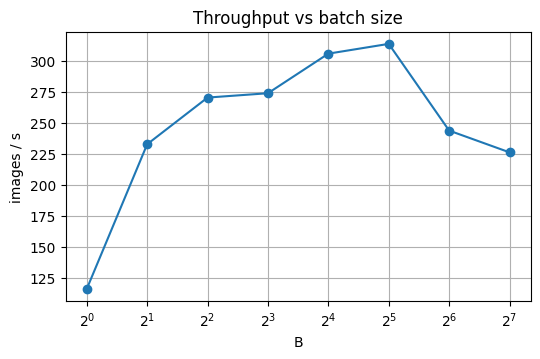

In [4]:
batches = [1, 2, 4, 8, 16, 32, 64, 128]
sweep = pd.DataFrame([measure(B) for B in batches]).set_index("B")
display(sweep.round(2))

stages = ["pre", "h2d", "gpu", "d2h", "post"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sweep[stages].plot(kind="bar", stacked=True, ax=ax[0], colormap="tab10")
ax[0].set_title("Latency breakdown per batch (ms)"); ax[0].set_ylabel("ms"); ax[0].set_xlabel("batch size")
(sweep[stages].div(sweep[stages].sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, ax=ax[1], colormap="tab10")
ax[1].set_title("Share of end-to-end time (%)"); ax[1].set_ylabel("%"); ax[1].set_xlabel("batch size")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
sweep["img_per_s"].plot(marker="o", ax=ax); ax.set_xscale("log", base=2)
ax.set_title("Throughput vs batch size"); ax.set_ylabel("images / s"); ax.grid(True); plt.show()

## 4. Fix-and-compare experiments
Each experiment changes **one** thing, so any gain is attributable. Batch size is fixed at 32.

| Experiment | Targets which stage |
|---|---|
| Pinned memory | [2] H2D, [4] D2H (page-locked memory lets DMA run at full PCIe speed) |
| FP16 | [2] fewer bytes over PCIe, [3] tensor cores |
| channels_last | [3] tensor-core-friendly memory layout |
| All combined | everything |

,pre,h2d,gpu,d2h,post,wall,img_per_s,speedup_x
baseline fp32,11.50,4.58,90.18,0.25,0.63,107.36,298.06,1.00
+ pinned memory,11.57,5.14,90.91,0.25,0.66,108.73,294.30,0.99
fp16,48.06,2.64,36.12,0.31,0.70,88.11,363.16,1.22
channels_last,41.36,4.73,105.81,0.24,0.64,153.03,209.11,0.70
fp16+pinned+chlast,47.86,4.40,29.28,0.21,0.63,82.60,387.41,1.30


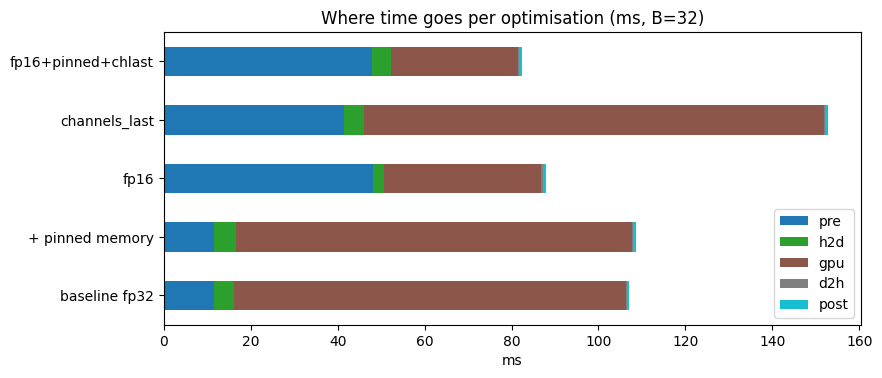

In [5]:
configs = {
    "baseline fp32":        dict(),
    "+ pinned memory":      dict(pinned=True),
    "fp16":                 dict(fp16=True),
    "channels_last":        dict(channels_last=True),
    "fp16+pinned+chlast":   dict(fp16=True, pinned=True, channels_last=True),
}
res = {k: measure(B=32, **v) for k, v in configs.items()}
exp = pd.DataFrame(res).T[stages + ["wall", "img_per_s"]]
exp["speedup_x"] = exp.loc["baseline fp32", "wall"] / exp["wall"]
display(exp.round(2))
exp[stages].plot(kind="barh", stacked=True, figsize=(9, 3.8), colormap="tab10")
plt.title("Where time goes per optimisation (ms, B=32)"); plt.xlabel("ms"); plt.show()

## 5. Kernel-launch overhead and GPU idle time
At batch 1, ResNet-50 launches hundreds of tiny kernels. If the **CPU cannot submit work as fast as the GPU finishes it**, the GPU sits idle. We compare *GPU kernel time* with *wall-clock time* for the same forward pass. A big gap means CPU/launch-bound.

In [6]:
@torch.inference_mode()
def launch_gap(B, iters=50):
    m = copy.deepcopy(base_model).to(dev)
    x = torch.randn(B, 3, 224, 224, device=dev)
    for _ in range(10): m(x)
    torch.cuda.synchronize()
    s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
    t0 = time.perf_counter(); s.record()
    for _ in range(iters): m(x)
    e.record(); torch.cuda.synchronize()
    wall = (time.perf_counter() - t0) * 1e3 / iters
    gpu = s.elapsed_time(e) / iters
    # CPU time to merely *enqueue* the work (no waiting for GPU)
    t0 = time.perf_counter()
    for _ in range(iters): m(x)
    enqueue = (time.perf_counter() - t0) * 1e3 / iters
    torch.cuda.synchronize()
    return dict(B=B, gpu_ms=gpu, wall_ms=wall, cpu_enqueue_ms=enqueue,
                cpu_bound=enqueue > 0.9 * gpu)

lg = pd.DataFrame([launch_gap(b) for b in [1, 2, 4, 8, 16, 32]]).set_index("B")
display(lg.round(3))
print("cpu_bound=True  → CPU (Python + launch overhead) cannot keep the GPU fed. Fix: larger batch, CUDA Graphs, torch.compile(mode='reduce-overhead').")

,gpu_ms,wall_ms,cpu_enqueue_ms,cpu_bound
B,,,,
1,6.820,6.822,9.026,True
2,9.565,9.567,9.189,True
4,14.192,14.196,12.996,True
8,27.896,27.899,25.684,True
16,52.883,52.885,48.960,True
32,108.332,108.333,101.187,True


cpu_bound=True  → CPU (Python + launch overhead) cannot keep the GPU fed. Fix: larger batch, CUDA Graphs, torch.compile(mode='reduce-overhead').


### 5b. CUDA Graphs: remove launch overhead entirely
A CUDA Graph records the whole kernel sequence once and replays it with a *single* launch.

In [7]:
@torch.inference_mode()
def cuda_graph_compare(B=1, iters=100):
    m = copy.deepcopy(base_model).to(dev)
    static_x = torch.randn(B, 3, 224, 224, device=dev)
    s = torch.cuda.Stream()
    s.wait_stream(torch.cuda.current_stream())
    with torch.cuda.stream(s):
        for _ in range(5): m(static_x)
    torch.cuda.current_stream().wait_stream(s)
    g = torch.cuda.CUDAGraph()
    with torch.cuda.graph(g):
        static_y = m(static_x)

    def time_it(fn):
        torch.cuda.synchronize(); t = time.perf_counter()
        for _ in range(iters): fn()
        torch.cuda.synchronize()
        return (time.perf_counter() - t) * 1e3 / iters
    eager = time_it(lambda: m(static_x))
    graph = time_it(g.replay)
    return eager, graph

try:
    eager, graph = cuda_graph_compare(B=1)
    print(f"B=1  eager: {eager:.2f} ms | CUDA Graph: {graph:.2f} ms | speedup {eager/graph:.2f}x")
except Exception as ex:
    print("CUDA Graph capture failed:", ex)

B=1  eager: 6.84 ms | CUDA Graph: 5.07 ms | speedup 1.35x


## 6. Kernel-level view with `torch.profiler`
This zooms into stage [3]: which kernels dominate, and how much time is spent in memcpy vs compute. Chrome trace is exported so you can open `trace.json` at `chrome://tracing` or [ui.perfetto.dev](https://ui.perfetto.dev) to *see* the timeline (gaps between kernels = idle GPU).

In [8]:
from torch.profiler import profile, ProfilerActivity, schedule

m = copy.deepcopy(base_model).to(dev)
x = torch.randn(16, 3, 224, 224, device=dev)
with torch.inference_mode():
    for _ in range(5): m(x)
    torch.cuda.synchronize()
    with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA], record_shapes=True) as prof:
        for _ in range(5): m(x)
        torch.cuda.synchronize()

try:
    print(prof.key_averages().table(sort_by="cuda_time_total", row_limit=12, max_name_column_width=50))
except Exception:
    print(prof.key_averages().table(sort_by="device_time_total", row_limit=12, max_name_column_width=50))
prof.export_chrome_trace("trace.json")
print("Saved trace.json  (download from the Colab file browser)")

--------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                              Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
--------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                      aten::conv2d         0.42%       1.048ms        10.04%      25.062ms      94.575us       0.000us         0.00%     182.831ms     689.929us           265  
                                 aten::convolution         0.48%       1.202ms         9.62%      24.015ms      90.622us       0.000us         0.00%     182.831ms     689.929us           265  
                                at

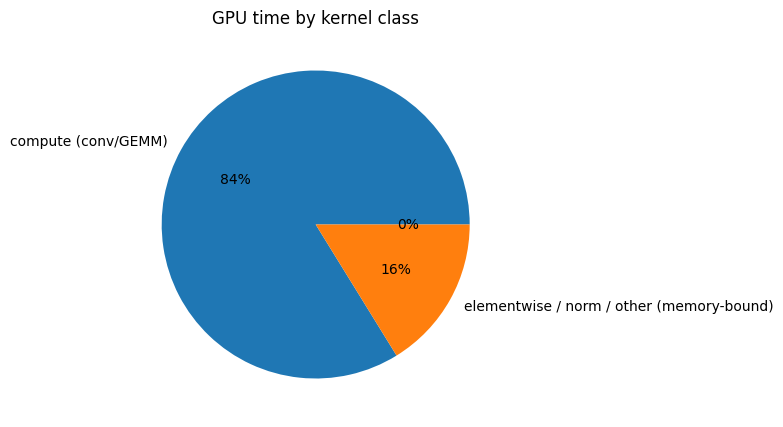

In [9]:
# Classify GPU time: GEMM/conv (compute) vs elementwise / norm (memory-bound) vs copies
rows = []
for ev in prof.key_averages():
    t = getattr(ev, "device_time_total", None)
    if t is None: t = getattr(ev, "cuda_time_total", 0)
    if t > 0: rows.append((ev.key, t))
kdf = pd.DataFrame(rows, columns=["kernel", "us"])
def cls(n):
    n = n.lower()
    if any(k in n for k in ["gemm", "conv", "cudnn", "cutlass", "wgrad", "sm80", "sm75", "implicit"]): return "compute (conv/GEMM)"
    if "memcpy" in n or "memset" in n: return "memory copy"
    return "elementwise / norm / other (memory-bound)"
kdf["class"] = kdf["kernel"].map(cls)
share = kdf.groupby("class")["us"].sum()
(share / share.sum() * 100).round(1).plot(kind="pie", autopct="%1.0f%%", figsize=(5, 5), ylabel="")
plt.title("GPU time by kernel class"); plt.show()

## 7. Roofline-style utilisation: are we near the hardware limit?
- **Achieved TFLOPS** = FLOPs of one forward ÷ GPU time.
- Compare with the card's peak. Low % with high GPU-busy time → memory-bound kernels or poor tensor-core use. Low % with low GPU-busy → feeding problem (CPU/PCIe).

In [10]:
from torch.utils.flop_counter import FlopCounterMode

def utilisation(B=32, fp16=False):
    m = copy.deepcopy(base_model).to(dev)
    if fp16: m = m.half()
    x = torch.randn(B, 3, 224, 224, device=dev, dtype=torch.float16 if fp16 else torch.float32)
    with torch.inference_mode():
        with FlopCounterMode(display=False) as fc:
            m(x)
        flops = fc.get_total_flops()
        for _ in range(10): m(x)
        torch.cuda.synchronize()
        s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        s.record()
        for _ in range(30): m(x)
        e.record(); torch.cuda.synchronize()
    ms = s.elapsed_time(e) / 30
    achieved = flops / (ms / 1e3) / 1e12
    peak, bw = gpu_peak(props.name, fp16)
    # weights are re-read each pass; this is a lower bound on bytes moved
    param_bytes = sum(p.numel() * p.element_size() for p in m.parameters())
    ai = flops / param_bytes
    return dict(precision="fp16" if fp16 else "fp32", B=B, gpu_ms=ms, achieved_TFLOPS=achieved,
                peak_TFLOPS=peak, util_pct=(100 * achieved / peak) if peak else None,
                arith_intensity_flop_per_byte=ai,
                ridge_point=(peak * 1e12 / (bw * 1e9)) if peak else None)

util = pd.DataFrame([utilisation(32, False), utilisation(32, True)])
display(util.round(2))
print("If arith_intensity (weights-only bound) is far below ridge_point, memory traffic, not math, caps performance.")

,precision,B,gpu_ms,achieved_TFLOPS,peak_TFLOPS,util_pct,arith_intensity_flop_per_byte,ridge_point
0,fp32,32,112.26,2.33,8.1,28.78,2560.04,25.31
1,fp16,32,48.03,5.45,65.0,8.38,5120.07,203.12


If arith_intensity (weights-only bound) is far below ridge_point, memory traffic, not math, caps performance.


## 8. Automatic bottleneck verdict
Rule-based classifier over the measured breakdown. It names the dominant stage, then states the fix. Change `B` to test other batch sizes.

In [11]:
def verdict(row):
    total = row[stages].sum()
    share = (row[stages] / total * 100).to_dict()
    top = max(share, key=share.get)
    gpu_busy = row["gpu_busy_%"]
    msgs = []
    if top == "pre":
        msgs.append("CPU PREPROCESS-bound: GPU is starved. Use DataLoader workers, uint8 transfer + GPU-side normalise, DALI/nvJPEG.")
    elif top in ("h2d", "d2h"):
        msgs.append("PCIe TRANSFER-bound: Use pinned memory, send uint8/fp16 instead of fp32, overlap copies with compute (streams, non_blocking).")
    elif top == "post":
        msgs.append("CPU POSTPROCESS-bound: move softmax/top-k/NMS to the GPU, return less data.")
    else:
        msgs.append("GPU COMPUTE-bound: this is the healthy case. Use fp16/INT8, channels_last, TensorRT, torch.compile, or a smaller model.")
    if gpu_busy < 50:
        msgs.append(f"GPU busy only {gpu_busy:.0f}% of wall time: pipeline is serial. Overlap stages with a producer/consumer queue and CUDA streams.")
    return share, msgs

for B in [1, 8, 32, 128]:
    share, msgs = verdict(sweep.loc[B])
    print(f"\n=== Batch {B} ===")
    print({k: f"{v:.0f}%" for k, v in share.items()})
    for s_ in msgs: print("  ->", s_)


=== Batch 1 ===
{'pre': '4%', 'h2d': '3%', 'gpu': '91%', 'd2h': '1%', 'post': '1%'}
  -> GPU COMPUTE-bound: this is the healthy case. Use fp16/INT8, channels_last, TensorRT, torch.compile, or a smaller model.

=== Batch 8 ===
{'pre': '11%', 'h2d': '5%', 'gpu': '83%', 'd2h': '1%', 'post': '1%'}
  -> GPU COMPUTE-bound: this is the healthy case. Use fp16/INT8, channels_last, TensorRT, torch.compile, or a smaller model.

=== Batch 32 ===
{'pre': '11%', 'h2d': '5%', 'gpu': '83%', 'd2h': '0%', 'post': '1%'}
  -> GPU COMPUTE-bound: this is the healthy case. Use fp16/INT8, channels_last, TensorRT, torch.compile, or a smaller model.

=== Batch 128 ===
{'pre': '32%', 'h2d': '4%', 'gpu': '64%', 'd2h': '0%', 'post': '1%'}
  -> GPU COMPUTE-bound: this is the healthy case. Use fp16/INT8, channels_last, TensorRT, torch.compile, or a smaller model.


## 9. Overlap demo: the payoff of fixing the serial path
Double-buffering with a second CUDA stream hides the H2D copy behind compute of the previous batch.

In [12]:
@torch.inference_mode()
def overlap_demo(B=32, iters=40):
    m = copy.deepcopy(base_model).to(dev).half().to(memory_format=torch.channels_last)
    host = [torch.randn(B, 3, 224, 224).half().pin_memory() for _ in range(2)]
    copy_stream = torch.cuda.Stream()
    for _ in range(5): m(host[0].to(dev))
    torch.cuda.synchronize()

    # serial: copy then compute, one stream
    t = time.perf_counter()
    for i in range(iters):
        xg = host[i % 2].to(dev, non_blocking=True)
        m(xg)
    torch.cuda.synchronize(); serial = (time.perf_counter() - t) * 1e3 / iters

    # overlapped: prefetch next batch on copy_stream while current computes
    t = time.perf_counter()
    with torch.cuda.stream(copy_stream):
        nxt = host[0].to(dev, non_blocking=True)
    for i in range(iters):
        torch.cuda.current_stream().wait_stream(copy_stream)
        cur = nxt
        cur.record_stream(torch.cuda.current_stream())
        with torch.cuda.stream(copy_stream):
            nxt = host[(i + 1) % 2].to(dev, non_blocking=True)
        m(cur)
    torch.cuda.synchronize(); over = (time.perf_counter() - t) * 1e3 / iters
    return serial, over

ser, ov = overlap_demo()
print(f"Serial: {ser:.2f} ms/batch | Overlapped: {ov:.2f} ms/batch | gain {ser/ov:.2f}x")

Serial: 39.82 ms/batch | Overlapped: 39.87 ms/batch | gain 1.00x


## 10. Summary template (fill with your numbers for the report)
| Item | Your finding |
|---|---|
| GPU / PCIe | from Section 1 |
| Dominant stage at B=1 | Section 3 / 8 |
| Dominant stage at B=128 | Section 3 / 8 |
| Best single optimisation | Section 4 `speedup_x` |
| Launch overhead evidence | Section 5 (`cpu_bound`, CUDA Graph speedup) |
| Hardware utilisation | Section 7 `util_pct` |
| Gain from overlap | Section 9 |

**Key takeaway:** end-to-end inference speed is set by the *slowest stage of the whole path*, not by the GPU's peak FLOPS. Measure first, then optimise the stage that dominates.